# 0_1build_vix_vrp.ipynb

Making sure path files work reliably

In [19]:
from pathlib import Path
import os

# Force working directory to repo root (assumes you opened the repo folder in VS Code)
REPO = Path.cwd()
print("CWD:", REPO)

# If accidentally opened the notebooks folder as workspace root, fix as follows:
if REPO.name == "notebooks":
    os.chdir(REPO.parent)
    REPO = Path.cwd()

print("Adjusted CWD:", REPO)


CWD: c:\Users\Andre\iCloud Drive_new\iCloudDrive\Desktop\Thesis\thesis-vrp-fomc
Adjusted CWD: c:\Users\Andre\iCloud Drive_new\iCloudDrive\Desktop\Thesis\thesis-vrp-fomc


Import relevant modules

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
from pathlib import Path
from pandas_datareader import data as pdr

# Create folders if needed
Path("data/processed").mkdir(parents=True, exist_ok=True)
Path("reports/figures").mkdir(parents=True, exist_ok=True)
Path("reports/tables").mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())


Working directory: c:\Users\Andre\iCloud Drive_new\iCloudDrive\Desktop\Thesis\thesis-vrp-fomc


Pull Data from FRED

In [21]:
start = "2016-01-01"  # Starting in 2016 because this is the earliest available SP500 FRED data. License restriction limits it to last 10 years of data.
end = "2026-02-05"  # freeze the vintage data for reproducibility
sp = pdr.DataReader("SP500", "fred", start, end)     # S&P 500 index level
vix = pdr.DataReader("VIXCLS", "fred", start, end)   # VIX close

df = sp.join(vix, how="inner").dropna()
df.columns = ["sp500", "vix"]
df = df.sort_index()

raw = sp.join(vix, how="inner").dropna()
raw.columns = ["sp500", "vix"]
raw.to_parquet("data/raw/fred_sp500_vix_vintage_2026-02-04.parquet")
print("Saved raw vintage:", raw.index.min(), raw.index.max(), raw.shape)

print("Rows:", len(df))
print(df.head())
print(df.tail())


Saved raw vintage: 2016-02-08 00:00:00 2026-02-05 00:00:00 (2514, 2)
Rows: 2514
              sp500    vix
DATE                      
2016-02-08  1853.44  26.00
2016-02-09  1852.21  26.54
2016-02-10  1851.86  26.29
2016-02-11  1829.08  28.14
2016-02-12  1864.78  25.40
              sp500    vix
DATE                      
2026-01-30  6939.03  17.44
2026-02-02  6976.44  16.34
2026-02-03  6917.81  18.00
2026-02-04  6882.72  18.64
2026-02-05  6798.40  21.77


Quick diagnostic

In [22]:
print("SP500 min/max:", sp.index.min(), sp.index.max(), sp.shape)
print("VIXCLS min/max:", vix.index.min(), vix.index.max(), vix.shape)
print(sys.executable)


SP500 min/max: 2016-02-08 00:00:00 2026-02-05 00:00:00 (2609, 1)
VIXCLS min/max: 2016-01-01 00:00:00 2026-02-05 00:00:00 (2635, 1)
c:\Users\Andre\anaconda3\envs\thesis-vrp\python.exe


Note: Since the data is available only from the last 10 years. It is worth considering starting in 2017

Build VRP: IVAR (Vix^{2}) - forward RVAR (approx. 1 month)

In [23]:
# Daily log returns
df["logret"] = np.log(df["sp500"]).diff()
df["ret2"] = df["logret"] ** 2

# Horizon: ~1 month = 22 trading days
h = 22

# Forward realized variance: sum of next h squared returns, annualized to variance units
df["rv_fwd"] = df["ret2"].rolling(h).sum().shift(-h) * (252 / h)

# Implied variance from VIX (VIX is annualized volatility in %)
df["iv"] = (df["vix"] / 100.0) ** 2

# Variance Risk Premium
df["vrp"] = df["iv"] - df["rv_fwd"]

# Keep a clean analysis slice where forward RV exists
vrp_df = df.dropna(subset=["rv_fwd", "iv", "vrp"]).copy()

print("Usable rows (after forward RV):", len(vrp_df))


Usable rows (after forward RV): 2492


Sanity check and summary stats

In [24]:
summary = vrp_df[["iv", "rv_fwd", "vrp"]].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T
print(summary)

# Quick checks you should expect to be true most of the time:
print("\nMean VRP:", vrp_df["vrp"].mean())
print("Share VRP > 0:", (vrp_df["vrp"] > 0).mean())


         count      mean       std       min        1%        5%       50%  \
iv      2492.0  0.039426  0.043808  0.008354  0.009309  0.011449  0.027606   
rv_fwd  2492.0  0.032778  0.079209  0.001381  0.002343  0.003861  0.014884   
vrp     2492.0  0.006648  0.071166 -0.803003 -0.193721 -0.027748  0.011393   

             95%       99%       max  
iv      0.096020  0.204723  0.683764  
rv_fwd  0.083733  0.356016  0.875130  
vrp     0.050795  0.110316  0.297440  

Mean VRP: 0.0066482941269691105
Share VRP > 0: 0.8298555377207063


Plots

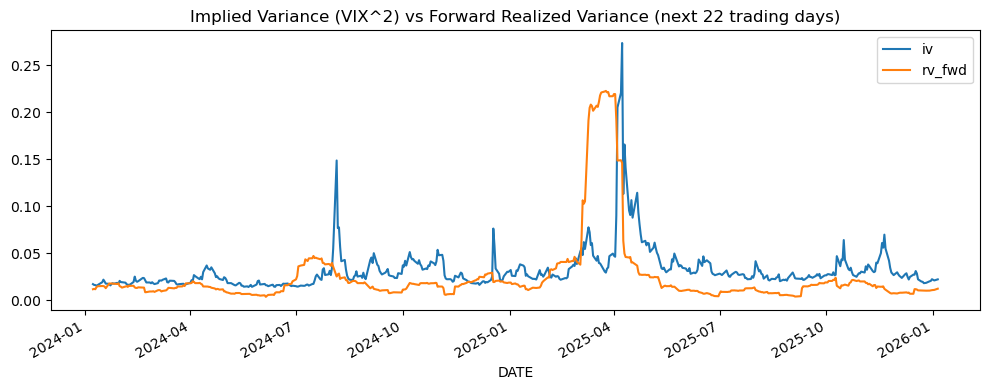

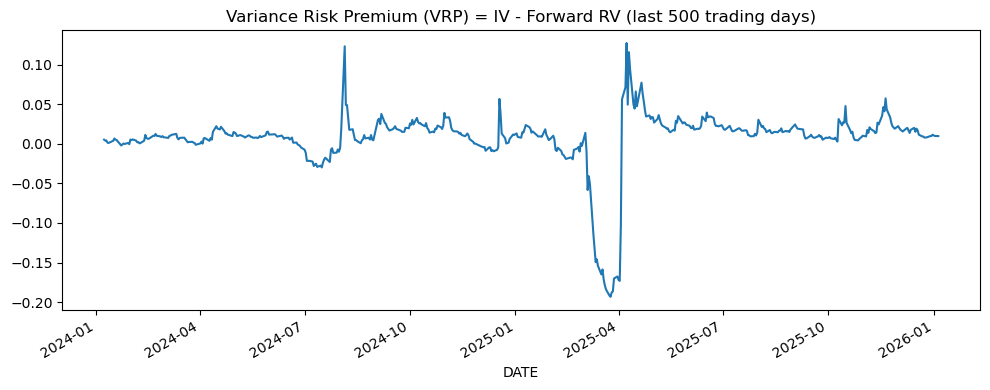

In [25]:
# Plot last ~2 years (about 500 trading days)
tail_n = 500

ax = vrp_df[["iv", "rv_fwd"]].tail(tail_n).plot(figsize=(10,4))
ax.set_title("Implied Variance (VIX^2) vs Forward Realized Variance (next 22 trading days)")
ax.figure.tight_layout()
ax.figure.savefig("reports/figures/iv_vs_rv_last500.png", dpi=200)
plt.show()

ax = vrp_df["vrp"].tail(tail_n).plot(figsize=(10,4))
ax.set_title("Variance Risk Premium (VRP) = IV - Forward RV (last 500 trading days)")
ax.figure.tight_layout()
ax.figure.savefig("reports/figures/vrp_last500.png", dpi=200)
plt.show()


Save outputs

In [26]:
# Save dataset (data/ is ignored by git — correct)
out_path = Path("data/processed/vrp_vix_daily.parquet")
vrp_df.reset_index().rename(columns={"DATE": "date"}).to_parquet(out_path, index=False)
print("Saved:", out_path)

# Save summary stats table for quick reuse in writing
summary.to_csv("reports/tables/vrp_summary_stats.csv")
print("Saved: reports/tables/vrp_summary_stats.csv")


Saved: data\processed\vrp_vix_daily.parquet
Saved: reports/tables/vrp_summary_stats.csv


Confirming the vrp parquet

In [27]:
Path("data/processed/vrp_vix_daily.parquet").exists()


True